# Workshop 1: exploring TCGA colon cancer data
*Curating Cancer Data, workshop 1 (analysis version). **INSTRUCTOR ANSWER / MARKING COPY: code filled in, model answers after each Discussion question***

**Aim.** A sequencing experiment produces a big matrix of numbers: one row per gene, one column per sample. Today you receive
that table (plus mutation calls and clinical information about the patients) as several files from two different sources. This data is all from the Cancer Genome Atlas study on Colorectal Adenocarcinoma: https://doi.org/10.1038/nature11252


**How this notebook works.**
- Run each code cell in order (click it, then press Shift+Enter).
- Some cells contain gaps marked `____` (or `____` inside quotes). **Replace each `____` with the correct value, then run the cell.** The comments tell you what to put. 
- If a cell gives an error, read the message (the last line is the useful one), check your gaps, and ask if you are stuck for more than a few minutes.
- Cells starting **Discussion** are questions to talk through with the people around you.

**Python cheat sheet (everything you need).**

| you see | it means |
|---|---|
| `df["col"]` | the column called `col` of the table `df` |
| `df.head()` | the first few rows of the table |
| `df[condition]` | keep only the rows where the condition is true |
| `==`, `!=`, `>` | equals, does not equal, greater than |
| `.sum(axis=0)` / `.sum(axis=1)` | add up down each column / across each row |
| `.mean()`, `.median()` | average, middle value |
| `.value_counts()` | count how many times each value appears |
| `# text` | a comment: ignored by Python, written for humans |

| part | topic |
|---|---|
| 1 | Orient: what is in the expression file? sample names, library size |
| 2 | Mutations: filters, how many mutations per tumour, MSI, VAF |
| 3 | Which genes are mutated? Make your own oncoprint |
| 4 | Expression: PCA, tumour vs normal, confounding, single genes |
| 5 | Judgement: t-SNE, what can't this data tell us |

## 0. Setup

In [1]:
## This is just setup - loading standard modules and checking that the correct files are present

import subprocess, sys, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
DATA = Path("starter_pack")

if not DATA.exists():                      # Colab: upload the starter_pack zip when asked
    try:
        from google.colab import files
        for name in files.upload():
            zipfile.ZipFile(name).extractall(".")
    except ImportError:
        pass
assert DATA.exists(), "Put the starter_pack folder next to this notebook (or upload the zip in Colab)."
print(sorted(p.name for p in DATA.iterdir()))
print((DATA / "README_provenance.md").read_text()[:1500])

['README_provenance.md', 'clinical_patients.tsv', 'clinical_samples.tsv', 'counts_xena_log2.tsv.gz', 'gene_map.csv', 'instructor_only_duplicates.csv', 'logcpm_tumour_normal.tsv.gz', 'mutations_subset.tsv.gz', 'sample_info.csv']
# Workshop 1 starter pack: TCGA colon adenocarcinoma

Built 2026-11-09 by `build_starter_pack.py`.

## Sources
- Expression: UCSC Xena GDC hub, TCGA-COAD star counts (GRCh38 / GENCODE annotation), values are log2(count + 1).
- Mutations and clinical data: cBioPortal, study `coadread_tcga_pan_can_atlas_2018` (mutation calls on GRCh37).
- Gene annotation: mygene.info query (a snapshot; annotation changes over time).

## What was done
- counts as downloaded: 60,660 genes x 514 samples
- short IDs shared by more than one column: 13 (26 columns involved)
- duplicate vials left in the pack for students to resolve
- counts written: 514 samples; sample type codes {'01': 471, '11': 41, '02': 1, '06': 1}
- primary tumours with both counts and cBioPortal annotation: 438
- 

Read the README above. Make a mental note of which reference genome each source uses; it matters in Part 2.

## Part 1. Orient

### 1.1 Load the gene expression file and find out what it is

In [2]:
# Load the RNA-seq expression matrix: rows = genes (Ensembl IDs), columns = samples (TCGA barcodes).
counts = pd.read_csv(DATA / "counts_xena_log2.tsv.gz", sep="\t", index_col=0)
print(counts.shape)          # (number of genes, number of samples)
counts.iloc[:5, :4]          # peek at the first 5 genes x first 4 samples

(19457, 514)


,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A
Ensembl_ID,,,,
ENSG00000000003.15,10.24555,12.02894,12.35122,9.63662
ENSG00000000005.6,2.32193,3.00000,1.58496,0.00000
ENSG00000000419.13,10.27030,9.72792,10.24436,10.56129
ENSG00000000457.14,8.50779,7.92481,7.85798,9.15482
ENSG00000000460.17,8.34873,6.82018,7.06609,8.15987


In [3]:
# Take the first 20 samples and ask simple questions about their values.
# Raw sequencing counts would be non-negative whole numbers with many exact zeros.
sub = counts.iloc[:, :20].to_numpy(dtype="float64")
print("min", sub.min(), " max", sub.max())
print("fraction of values that are whole numbers:", np.mean(np.isclose(sub, np.round(sub))))
print("fraction of values equal to exactly 0:", np.mean(sub == 0))

min 0.0  max 19.9103
fraction of values that are whole numbers: 0.21674718610268798
fraction of values equal to exactly 0: 0.15611862054787481


**Discussion.** Do you think this matrix is raw counts, normalised values, or something else? What in the output above and the readme tells you? (The file name says `counts`. Does the content agree?)

> **Model answer (instructor).** The values are not raw counts: the file is **log2(count + 1)** (README says so). Evidence: values run from 0 to about 20 (raw counts would reach millions), only about 64% are whole numbers, and 54% are exactly 0 (log2(0 + 1) = 0, i.e. genes with zero counts). The filename 'counts' describes the origin, not the content. Marking: full marks for spotting log scale/non-integers AND citing the README.

### 1.2 Undo the transform

**In plain English.** Counts can range from 0 to millions, so the file's authors squashed them with a *log2 transform*: `value = log2(count + 1)`. To get back to the counts we do the opposite: `count = 2 ** value - 1`. (`**` means 'to the power of'.)

In [4]:
# The file stores log2(count + 1). To get back to counts we reverse the transform:
#     x = log2(count + 1)   ->   count = 2**x - 1
# We convert to float64 first so the inversion does not add extra rounding error.
# Fill in the blanks: reverse x = log2(count + 1)  ->  count = 2 ** x - 1
raw = 2 ** counts.astype("float64") - 1

# If the inversion worked, the values should be (almost) whole numbers.
# "off" is the distance of each value (first 20 samples) from its nearest whole number.
values = raw.iloc[:, :20].to_numpy()
off = np.abs(values - np.round(values))
print("largest distance from a whole number:", off.max())
print("fraction of values within 0.01 of a whole number:", np.mean(off < 0.01))

largest distance from a whole number: 0.49836969323223457
fraction of values within 0.01 of a whole number: 0.9557999691627692


**Discussion.** How close to whole numbers did you get? What does that say about how precisely the file stores its values, and which genes will be least reliable after inversion (high counts or low counts)?

> **Model answer (instructor).** About 95% of values are within 0.01 of a whole number; the largest distance is about 0.50. So the file stores values to limited (float) precision, and inversion is only approximately exact. **High counts are least reliable**: the error in 2**x - 1 scales with the size of the value (a small error in log space becomes a large error in count space), whereas low counts round cleanly. Rounding recovers integers.

In [5]:
# The values are close enough to whole numbers that we can round them and treat them as counts from here on.
raw = raw.round()

### 1.3 Parse the barcodes - this is just manipulating the id of each patient to extract the releavnt information, for more information see: https://docs.gdc.cancer.gov/Encyclopedia/pages/TCGA_Barcode/

In [6]:
# Build a table (one row per column of the expression matrix) describing each sample.
# A TCGA barcode looks like TCGA-A6-2671-01A-01R-...; splitting on "-" gives its parts.

## This extracts the barcode for each patient
meta = pd.DataFrame({"barcode": counts.columns}, index=counts.columns)
## This splits the barcode into its parts
parts = meta["barcode"].str.split("-", expand=True)
## We can now group these barcode components
meta["tss"] = parts[1]                                          # tissue source site (the hospital / centre)
meta["participant"] = parts[0] + "-" + parts[1] + "-" + parts[2]  # the patient

# parts[3] looks like "01A": the first two characters are the sample type
# (01 = primary tumour, 11 = normal ...) and the remainder is the vial letter.
meta["sample_type"] = parts[3].str[:2]
meta["vial"] = parts[3].str[2:]

# patient + sample type = one biological sample (different vials of it share this ID)
meta["short_id"] = meta["participant"] + "-" + meta["sample_type"]

In [7]:
# Translate the numeric sample-type codes into readable names.
TYPE_NAMES = {"01": "Primary tumour", "02": "Recurrent tumour", "06": "Metastatic", "11": "Solid tissue normal"}
meta["type_name"] = meta["sample_type"].map(TYPE_NAMES).fillna("other")

## Print the results of the manipulation
print(meta["type_name"].value_counts())
print("tissue source sites:", meta["tss"].nunique())
meta.head()

type_name
Primary tumour         471
Solid tissue normal     41
Recurrent tumour         1
Metastatic               1
Name: count, dtype: int64
tissue source sites: 25


,barcode,tss,participant,sample_type,vial,short_id,type_name
TCGA-5M-AAT6-01A,TCGA-5M-AAT6-01A,5M,TCGA-5M-AAT6,01,A,TCGA-5M-AAT6-01,Primary tumour
TCGA-AA-3552-01A,TCGA-AA-3552-01A,AA,TCGA-AA-3552,01,A,TCGA-AA-3552-01,Primary tumour
TCGA-AA-3867-01A,TCGA-AA-3867-01A,AA,TCGA-AA-3867,01,A,TCGA-AA-3867-01,Primary tumour
TCGA-AD-6895-01A,TCGA-AD-6895-01A,AD,TCGA-AD-6895,01,A,TCGA-AD-6895-01,Primary tumour
TCGA-AA-3560-01A,TCGA-AA-3560-01A,AA,TCGA-AA-3560,01,A,TCGA-AA-3560-01,Primary tumour


**Discussion.** How many samples of each type are there? Which type would you worry about when making group comparisons, and why?

> **Model answer (instructor).** Roughly 471 primary tumours, 41 solid tissue normals, and 1 recurrent and 1 metastatic sample (counts include the 13 duplicated samples if the base file has not been de-duplicated; 458 primary tumours after removing them). Worry about the **normals** (only 41 vs ~460 tumours): unequal group sizes, and they are likely to differ technically (different library sizes, often from adjacent tissue of the same patients) so group differences may not be purely tumour biology. The single recurrent/metastatic samples cannot be used for any group comparison.

### 1.4 Library size

                     count  mean   std   min   25%   50%   75%   max
type_name                                                           
Metastatic             0.0  48.8   NaN  48.8  48.8  48.8  48.8  48.8
Primary tumour         0.0  33.4  14.9   1.4  20.3  34.1  45.1  77.2
Recurrent tumour       0.0  36.7   NaN  36.7  36.7  36.7  36.7  36.7
Solid tissue normal    0.0  47.2  10.5  23.2  39.8  45.5  54.6  66.6


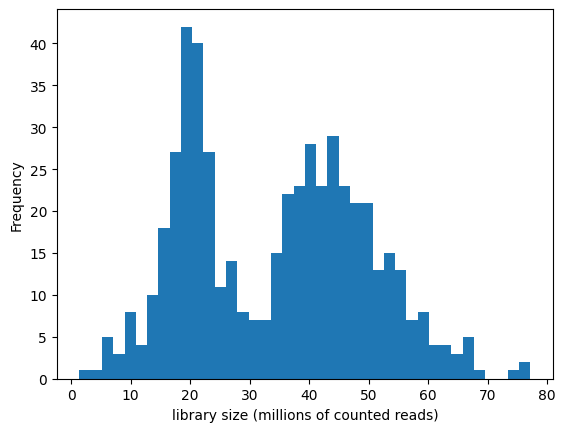

In [8]:
# Library size = total number of counted reads in a sample = the sum down each column of the raw counts.
meta["lib_size"] = raw.sum(axis=0)   # axis=0 means "add up down each column", axis=1 means "add up along the rows"

# Summarise library size (in millions of reads) for each sample type, then plot the overall distribution.
print((meta.groupby("type_name")["lib_size"].describe() / 1e6).round(1))
meta["lib_size"].div(1e6).plot.hist(bins=40)
plt.xlabel("library size (millions of counted reads)"); plt.show()

**Discussion.** Roughly how much does library size vary between samples? If you compared a gene's raw count between a sample at the bottom of this range and one at the top, what would go wrong?

> **Model answer (instructor).** Library size varies about 50-fold (about 1.5 to 82 million reads; typical primary tumour about 35 million, normals about 50 million). Comparing raw counts between a shallow and a deep sample would make nearly every gene look 'higher' in the deep sample purely because more reads were sequenced; a difference in depth would be mistaken for a difference in biology. Normalising (e.g. CPM) removes this. Normals having larger libraries on average would bias a tumour-vs-normal comparison of raw counts.

## Part 2. Mutations

### 2.1 Load and look

Somatic mutation calls come as a table with **one row per mutation per tumour**: which gene, what kind of change, how many sequencing reads support it, and so on.

In [9]:
# Load the somatic mutation calls: one row per mutation per tumour sample.
mut = pd.read_csv(DATA / "mutations_subset.tsv.gz", sep="\t", low_memory=False)
print(mut.shape, "rows;", mut["Tumor_Sample_Barcode"].nunique(), "tumours with at least one row")
print("reference build:", mut["NCBI_Build"].unique())     # which version of the human genome the positions refer to
mut.head(3)

(254670, 16) rows; 390 tumours with at least one row
reference build: ['GRCh37']


,Hugo_Symbol,NCBI_Build,Chromosome,Start_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,t_ref_count,t_alt_count,HGVSp_Short,FILTER,NCALLERS,n_depth,t_depth
0,DMBT1,GRCh37,10,124399948,Silent,SNP,T,C,TCGA-3L-AA1B-01,109,22,p.Y2316=,PASS,4,115,131
1,C10orf90,GRCh37,10,128193330,Missense_Mutation,SNP,C,T,TCGA-3L-AA1B-01,46,18,p.V147M,PASS,5,63,64
2,WDFY4,GRCh37,10,49997997,Missense_Mutation,SNP,C,T,TCGA-3L-AA1B-01,125,24,p.R1345W,PASS,4,148,149


**Discussion.** The expression data uses genome build GRCh38 and the mutation calls use GRCh37, so you could not match them by genomic position. What would you match them on instead, and what could go wrong?

> **Model answer (instructor).** Match on **gene symbol** (Hugo_Symbol) and, for samples, the patient/sample ID parts of the TCGA barcode. Things that can go wrong: gene symbols change over time or have aliases; one symbol can map to several Ensembl IDs (and some IDs to no symbol); different annotation versions between sources; and joining by symbol ignores which transcript/position was affected. Coordinates cannot be compared because GRCh37 and GRCh38 positions differ (would need a liftover).

### 2.2 Which mutation calls can we trust?

The `FILTER` column records whether the variant-calling software considered each call reliable (`PASS`) or flagged a problem (for example, a likely sequencing artefact).

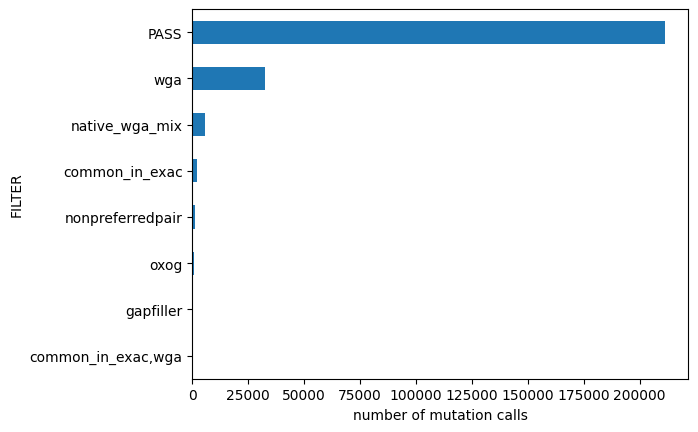

fraction not PASS: 0.17


In [10]:
# How many calls have each FILTER value? (PASS = the caller considers the call reliable)
filter_counts = mut["FILTER"].value_counts(dropna=False).head(8)
filter_counts.plot.barh()
plt.xlabel("number of mutation calls"); plt.gca().invert_yaxis(); plt.show()

# (mut["FILTER"] != "PASS") is True/False for each row; the mean of True/False values is the fraction that are True.
# Fill in the blank: the fraction of calls that are NOT "PASS"
frac_not_pass = (mut["FILTER"] != "PASS").mean()
print("fraction not PASS:", round(frac_not_pass, 3))

# Keep only the calls that passed the filters, from here on.
mut_pass = mut[mut["FILTER"] == "PASS"].copy()

**Discussion.** Would you keep the non-PASS calls if you were (a) counting driver mutations in the gene APC, (b) estimating each tumour's overall mutation burden? Justify each.

> **Model answer (instructor).** Best answer: **neither**, or at least be explicit. Non-PASS calls are those the caller flagged as likely artefacts (e.g. `oxog` oxidation artefacts, `wga` amplification artefacts) or common germline variants (`common_in_exac`). (a) Driver counting: including artefacts adds false positives and germline variants are not somatic, so excluding is safer; accept 'keep' only if it argues APC drivers are mostly obvious truncating hits and that sensitivity matters more than specificity. (b) Burden: artefacts inflate the count, and rates of non-PASS calls vary between samples, so including them adds noise. About 17% of calls are not PASS.

### 2.3 Which mutations change the protein?

Not every mutation matters equally. A **silent** mutation changes the DNA but not the protein; a **missense** mutation swaps one amino acid; a **nonsense** or **frame-shift** mutation usually destroys the protein. We will count only mutations that change the protein ("non-silent").

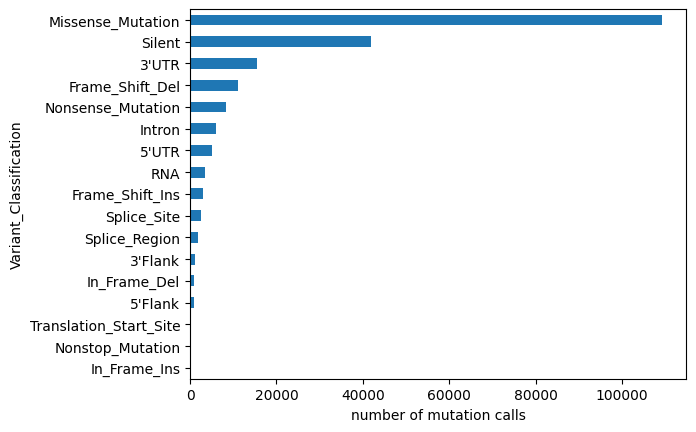

135578 non-silent PASS mutation calls


In [11]:
# How many calls of each variant type are there among the PASS calls?
mut_pass["Variant_Classification"].value_counts().plot.barh()
plt.xlabel("number of mutation calls"); plt.gca().invert_yaxis(); plt.show()

# The variant types that change the protein (or plausibly do). Everything else (Silent, Intron, UTR ...) is ignored.
NONSILENT = {"Missense_Mutation", "Nonsense_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins", "Splice_Site",
             "In_Frame_Del", "In_Frame_Ins", "Translation_Start_Site", "Nonstop_Mutation"}

# Keep only the non-silent calls. Fill in the blank: .isin(X) is True when a value is in the collection X.
ns = mut_pass[mut_pass["Variant_Classification"].isin(NONSILENT)]
print(len(ns), "non-silent PASS mutation calls")

**Discussion.** Pick one variant type that is in the NONSILENT set and one that is not, and say in one sentence why each is on its side. Is `Splice_Site` an easy call?

> **Model answer (instructor).** Examples. In NONSILENT: Missense (changes an amino acid), Nonsense/Frame_Shift (truncate or destroy the protein), In_Frame (adds/removes amino acids). Not in NONSILENT: Silent (same amino acid), Intron/UTR/Flank (outside the coding sequence). `Splice_Site` is **not an easy call**: it can disrupt splicing and cause exon skipping or frame shift (damaging), but some splice-site changes have no effect; it is included here as non-silent by convention.

### 2.4 How many mutations does each tumour have?

Now a first look at a distribution. We count the non-silent PASS mutations in each tumour, and compare with a second measure: the **MANTIS score**, which measures microsatellite instability (MSI), a sign that the cell's DNA mismatch repair is faulty. (We keep only the tumours that have mutation data; 48 tumours have none at all, so we do not know their mutation count.)

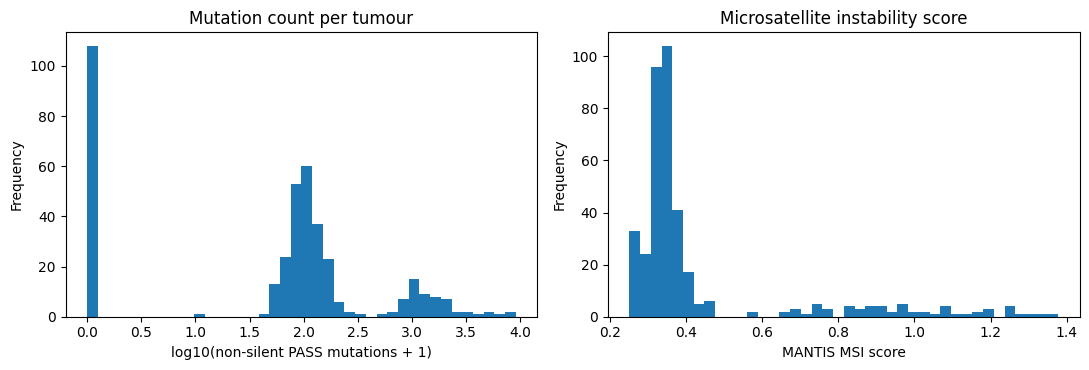

In [12]:
# Load the clinical table (one row per tumour sample) and keep tumours that have mutation data.
clin = pd.read_csv(DATA / "clinical_samples.tsv", sep="\t").set_index("SAMPLE_ID")
clin = clin[clin.index.isin(mut["Tumor_Sample_Barcode"])]

# Count the non-silent PASS mutations per tumour. Fill in the blank: .size() counts the rows in each group.
per_tumour = ns.groupby("Tumor_Sample_Barcode").size()
clin["n_nonsilent"] = per_tumour
# Tumours with data but no non-silent PASS rows really have zero mutations. Fill in the blank with that number.
clin["n_nonsilent"] = clin["n_nonsilent"].fillna(0)

# Two tumours have no MANTIS score; we leave them out.
clin = clin.dropna(subset=["MSI_SCORE_MANTIS"])

# Plot both distributions. Mutation counts span orders of magnitude, so we plot log10(count + 1).
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
np.log10(clin["n_nonsilent"] + 1).plot.hist(bins=40, ax=ax[0])
ax[0].set_xlabel("log10(non-silent PASS mutations + 1)"); ax[0].set_title("Mutation count per tumour")
clin["MSI_SCORE_MANTIS"].plot.hist(bins=40, ax=ax[1])
ax[1].set_xlabel("MANTIS MSI score"); ax[1].set_title("Microsatellite instability score")
plt.tight_layout(); plt.show()

**Discussion.** Look at both histograms. Is there a clear group of tumours with a very high mutation count ("hypermutators")? Is there a clear gap in the MANTIS score?

> **Model answer (instructor).** Yes: the mutation-count histogram (log scale) has a clear separate group at roughly 1,000 mutations (~10x higher than the bulk at about 100); about 20% of tumours. The MANTIS histogram has a bulk of low scores (about 0.25-0.40) and a smaller group of higher scores, with a **valley rather than a perfectly empty gap** (a few tumours lie in between around 0.4-0.6).

msi_group
MSS         311
MSI-high     77
Name: count, dtype: int64


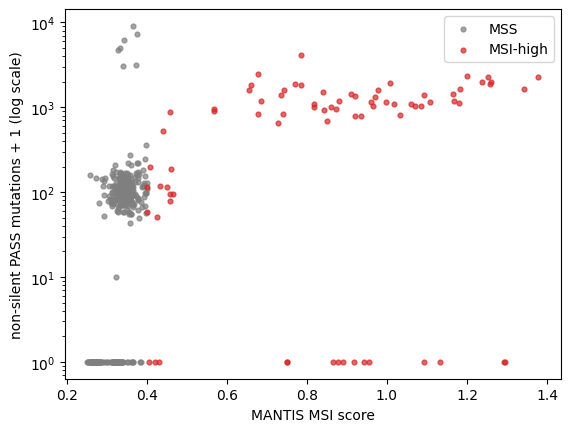

msi_group
MSI-high    994.0
MSS          83.0
Name: n_nonsilent, dtype: float64


In [13]:
# Choose a cut-off from the right-hand histogram: look for the valley between the two groups.
# Scores above the cut-off are called "MSI-high"; the rest are "MSS" (microsatellite stable).
MSI_CUTOFF = 0.4
clin["msi_group"] = np.where(clin["MSI_SCORE_MANTIS"] > MSI_CUTOFF, "MSI-high", "MSS")
print(clin["msi_group"].value_counts())

# Does MSI go with the number of mutations? Plot every tumour, coloured by group.
for group, colour in [("MSS", "tab:grey"), ("MSI-high", "tab:red")]:
    rows = clin[clin["msi_group"] == group]
    plt.scatter(rows["MSI_SCORE_MANTIS"], rows["n_nonsilent"] + 1, s=12, alpha=0.7, c=colour, label=group)
plt.yscale("log")                                   # log scale for the mutation count
plt.xlabel("MANTIS MSI score"); plt.ylabel("non-silent PASS mutations + 1 (log scale)"); plt.legend()
plt.show()

# Median number of mutations in each group.
print(clin.groupby("msi_group")["n_nonsilent"].median())

**Discussion.** Does the MSI-high group coincide with the hypermutated group? What are the median counts in the two groups? Give one biological reason why they should be linked (see the lecture). What would a wrong cut-off do to your MSI-high group?

> **Model answer (instructor).** Largely yes: 77 MSI-high tumours with a **median of about 994** non-silent mutations vs **about 83** in the 311 MSS tumours (at cut-off 0.4). Biology: MSI-high means the DNA mismatch-repair system (MLH1/MSH2/MSH6/PMS2) is defective, so replication errors, especially at repeats, are not corrected and mutations accumulate (hypermutation). A cut-off too low includes MSS tumours in the MSI-high group (diluting it, lowering the group's mutation count); too high drops true MSI-high tumours into the MSS group (contaminating MSS with hypermutators). Any cut-off in the valley (about 0.4-0.6) is acceptable if justified. Note a few tumours with a high score but almost no PASS non-silent calls: calling issues or data gaps (discussion point).

### 2.5 Variant allele fraction (VAF)

The **variant allele fraction** is the proportion of sequencing reads at a position that carry the mutation: `VAF = (reads with the mutation) / (total reads at that position)`. In a pure sample of cells with one mutant copy of a gene, we would expect a VAF of 0.5.

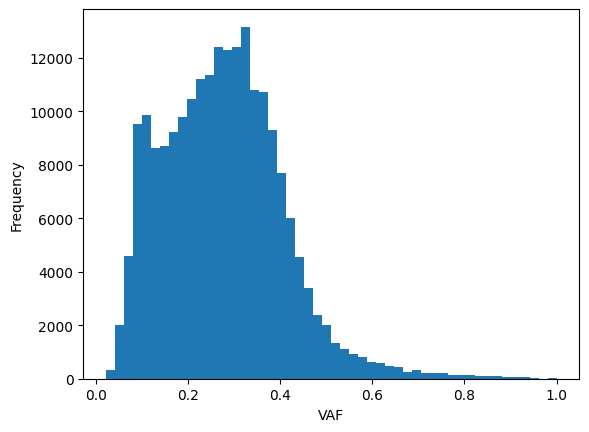

median VAF: 0.273 | fraction above 0.5: 0.042


In [14]:
# Only rows with at least one read can have a VAF (we cannot divide by zero).
vaf_df = mut_pass[mut_pass["t_depth"] > 0].copy()
# Fill in the blanks. Columns: "t_alt_count" = reads carrying the mutation; "t_depth" = total reads at the site.
vaf_df["vaf"] = vaf_df["t_alt_count"] / vaf_df["t_depth"]

vaf_df["vaf"].plot.hist(bins=50)
plt.xlabel("VAF"); plt.show()
print("median VAF:", round(vaf_df["vaf"].median(), 3),
      "| fraction above 0.5:", round((vaf_df["vaf"] > 0.5).mean(), 3))

**Discussion.** Almost no mutation has a VAF above 0.5, and the median is well below it. Why? Think about what else is in a tumour sample besides cancer cells that carry the mutation.

> **Model answer (instructor).** Median VAF is about 0.27 and only about 4% of calls are above 0.5. VAF is diluted by (1) **tumour purity**: normal stromal and immune cells carry no mutation; (2) **subclonality**: not all cancer cells carry the mutation; (3) **copy number / ploidy**: if the mutant copy is one of several copies; and heterozygosity (one mutant allele of two gives at most 0.5 even in a pure sample). Values above 0.5 need loss of the wild-type allele or copy gain of the mutant allele.

## Part 3. Which genes are mutated? Make an oncoprint

### 3.1 Rows are not samples

A gene can be mutated more than once in the same tumour. So there are two different questions we can ask: *how many mutation rows are in this gene?* and *in how many different tumours is this gene mutated?*

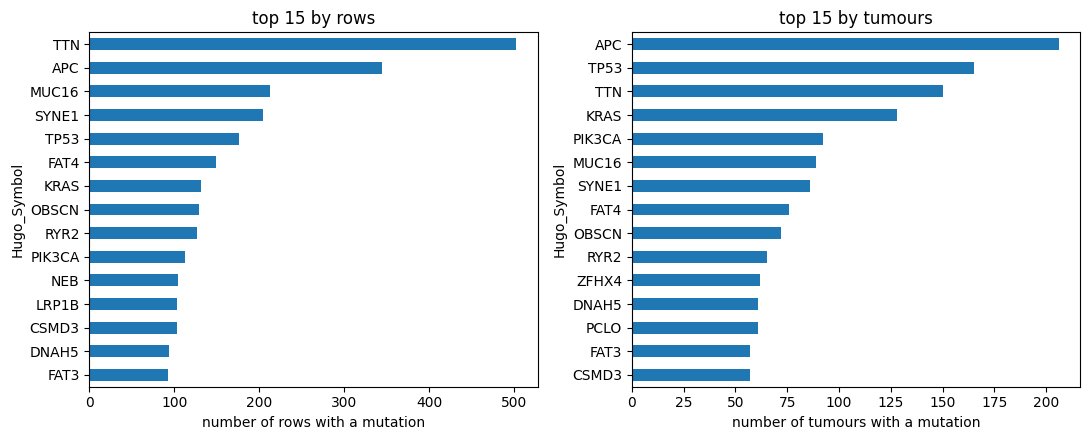

,rows,tumours,percent_of_tumours
Hugo_Symbol,,,
APC,344,206,53.1
TP53,176,165,42.5
TTN,502,150,38.7
KRAS,131,128,33.0
PIK3CA,112,92,23.7
MUC16,212,89,22.9
SYNE1,204,86,22.2
FAT4,149,76,19.6


In [15]:
# For each gene, count (a) the number of mutation rows and (b) the number of different tumours with a mutation.
# Fill in the blank: "nunique" counts the number of different values.
tumours_with_data = ns[ns["Tumor_Sample_Barcode"].isin(clin.index)]
gene_tbl = tumours_with_data.groupby("Hugo_Symbol").agg(rows=("Tumor_Sample_Barcode", "size"),
                                                        tumours=("Tumor_Sample_Barcode", "nunique"))
gene_tbl["percent_of_tumours"] = (100 * gene_tbl["tumours"] / len(clin)).round(1)

# Plot the 15 genes with the most mutation ROWS next to the 15 with the most mutated TUMOURS.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, column in zip(ax, ["rows", "tumours"]):
    top = gene_tbl[column].sort_values(ascending=False).head(15)
    top.plot.barh(ax=a); a.invert_yaxis(); a.set_xlabel(f"number of {column} with a mutation"); a.set_title(f"top 15 by {column}")
plt.tight_layout(); plt.show()
gene_tbl.sort_values("tumours", ascending=False).head(8)

**Discussion.** Which genes are in one plot but not the other? What does each plot answer? Why does it matter that we counted tumours rather than rows when we want to say 'what percentage of colon cancers have an APC mutation'?

> **Model answer (instructor).** TTN, MUC16, SYNE1 and other very large genes rank highly by **rows** (TTN is first with about 500 rows) but lower by **tumours** (TTN about 150 tumours, third); APC (about 344 rows, 206 tumours) and TP53, KRAS, PIK3CA rank higher by tumours. The rows plot answers 'where are most mutation calls?' and is distorted by tumours with many mutations and by gene length; the tumours plot answers 'how many patients are affected?'. For 'what percentage of colon cancers have an APC mutation' the unit must be the tumour: counting rows would double-count tumours with several APC mutations (APC has about 1.7 rows per mutated tumour), and the denominator must also be tumours (here 388, those with mutation data).

### 3.2 Build the oncoprint table

An **oncoprint** is the standard way to display mutations across a cohort. Each **row is a gene**, each **column is a tumour**, and the colour of each little rectangle says what kind of mutation that tumour has in that gene (grey = none).

First we turn the mutation list into a table with **one row per tumour and one column per gene**, where the value says how damaging the mutation is. If a tumour has several mutations in the same gene, we keep the most damaging one.

In [16]:
# A number for each kind of mutation: bigger = more damaging. 0 will mean "no mutation".
MUTATION_CODE = {"Missense_Mutation": 1,                                    # swaps one amino acid
                 "In_Frame_Del": 2, "In_Frame_Ins": 2,                       # adds / removes whole amino acids
                 "Nonsense_Mutation": 3, "Frame_Shift_Del": 3, "Frame_Shift_Ins": 3,   # truncate the protein
                 "Splice_Site": 3, "Translation_Start_Site": 3, "Nonstop_Mutation": 3}

def make_matrix(genes):
    """Returns a table: one row per tumour, one column per gene, value = most damaging mutation code (0 = none)."""
    # 1. keep only the mutations in our genes, in tumours we are analysing
    rows = ns[ns["Hugo_Symbol"].isin(genes) & ns["Tumor_Sample_Barcode"].isin(clin.index)].copy()
    # 2. replace each mutation type by its number
    rows["code"] = rows["Variant_Classification"].map(MUTATION_CODE)
    # 3. for each (tumour, gene) pair keep the biggest code. Fill in the blank: .max() takes the largest value.
    best = rows.groupby(["Tumor_Sample_Barcode", "Hugo_Symbol"])["code"].max()
    # 4. spread into a table (genes become columns); pairs with no mutation become 0
    matrix = best.unstack(fill_value=0)
    # 5. make sure every tumour and every gene is present, in our chosen order
    return matrix.reindex(index=clin.index, columns=genes, fill_value=0)

# Try it on the 12 genes with the most mutated tumours.
most_mutated = gene_tbl.sort_values("tumours", ascending=False).head(12).index.tolist()
matrix = make_matrix(most_mutated)
print(matrix.shape, "= tumours x genes")
matrix.iloc[:8, :6]

(388, 12) = tumours x genes


Hugo_Symbol,APC,TP53,TTN,KRAS,PIK3CA,MUC16
SAMPLE_ID,,,,,,
TCGA-3L-AA1B-01,3,0,0,0,1,0
TCGA-4N-A93T-01,0,1,0,1,0,0
TCGA-4T-AA8H-01,3,0,0,1,0,0
TCGA-5M-AAT4-01,3,1,0,1,1,0
TCGA-5M-AAT6-01,3,0,3,1,0,1
TCGA-5M-AATE-01,3,1,3,1,1,0
TCGA-A6-2671-01,3,3,0,0,0,0
TCGA-A6-2674-01,0,0,1,1,0,0


### 3.3 Draw it

The next cell defines a function that draws the oncoprint from the table. **You do not need to read it line by line**, but the comments explain each step: it sorts the tumours so that tumours with the same mutations are next to each other, then draws the table as a coloured grid, and adds a strip along the top showing which tumours are MSI-high.

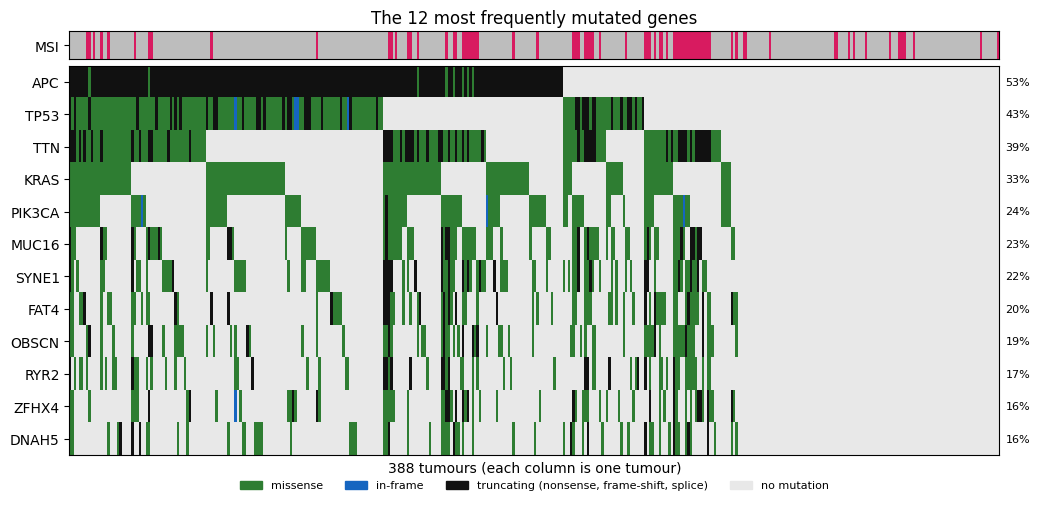

In [17]:
# HELPER FUNCTION - just run this cell, no changes needed.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def draw_oncoprint(matrix, title, sort_by_msi=False):
    genes = list(matrix.columns)

    # Sort the tumours: those mutated in the first gene come first, then the second gene, and so on.
    # (If sort_by_msi is True, the MSI-high tumours are put first, in a block of their own.)
    is_mutated = (matrix > 0).copy()
    sort_columns = genes
    if sort_by_msi:
        is_mutated["MSI-high"] = clin.loc[matrix.index, "msi_group"] == "MSI-high"
        sort_columns = ["MSI-high"] + genes
    order = is_mutated.sort_values(by=sort_columns, ascending=False).index
    matrix = matrix.loc[order]

    # Two panels: a thin strip for MSI status on top, the oncoprint grid below.
    fig, (ax_msi, ax) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True,
                                     gridspec_kw={"height_ratios": [1, 14], "hspace": 0.03})

    # The grid: one coloured square per (gene, tumour). 0 = none, 1 = missense, 2 = in-frame, 3 = truncating.
    colours = ["#e8e8e8", "#2e7d32", "#1565c0", "#111111"]
    ax.imshow(matrix.T.to_numpy(), aspect="auto", cmap=ListedColormap(colours), vmin=0, vmax=3, interpolation="nearest")
    ax.set_yticks(range(len(genes))); ax.set_yticklabels(genes)
    ax.set_xticks([]); ax.set_xlabel(f"{matrix.shape[0]} tumours (each column is one tumour)")

    # The percentage of tumours with a mutation in each gene, written at the right-hand edge.
    for y, gene in enumerate(genes):
        ax.text(matrix.shape[0] + 2, y, f"{100 * (matrix[gene] > 0).mean():.0f}%", va="center", fontsize=8)

    # The MSI strip: pink = MSI-high, grey = MSS.
    msi_high = (clin.loc[matrix.index, "msi_group"] == "MSI-high").astype(int).to_numpy()[None, :]
    ax_msi.imshow(msi_high, aspect="auto", cmap=ListedColormap(["#bdbdbd", "#d81b60"]), interpolation="nearest")
    ax_msi.set_yticks([0]); ax_msi.set_yticklabels(["MSI"]); ax_msi.set_xticks([]); ax_msi.set_title(title)

    # A legend explaining the colours.
    legend = [Patch(color=colours[1], label="missense"), Patch(color=colours[2], label="in-frame"),
              Patch(color=colours[3], label="truncating (nonsense, frame-shift, splice)"),
              Patch(color=colours[0], label="no mutation")]
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=4, frameon=False, fontsize=8)
    plt.show()

draw_oncoprint(matrix, "The 12 most frequently mutated genes")

**Discussion.** Look at the genes in this plot. Some are famous colorectal cancer genes (APC, TP53, KRAS); others (e.g. TTN, MUC16, SYNE1) are very large genes that are not thought to drive cancer. Why might very large genes pick up many mutations by chance? Which tumours carry most of these mutations?

> **Model answer (instructor).** Larger genes have more bases and so more chances of random mutation (and some, like TTN, also have late replication / low expression, giving higher background mutation rates), so they are mutated frequently without being drivers. These mutations are concentrated in the **hypermutated (MSI-high) tumours**, which carry hundreds to thousands of mutations, so passengers appear 'frequent' purely because of a few tumours. Frequency alone is not evidence of being a driver.

### 3.4 Use biology to choose the genes

Instead of the most frequent genes, we now choose genes that are known from the literature to be involved in colorectal cancer, and put the MSI-high tumours together in one block so we can compare them with the rest.

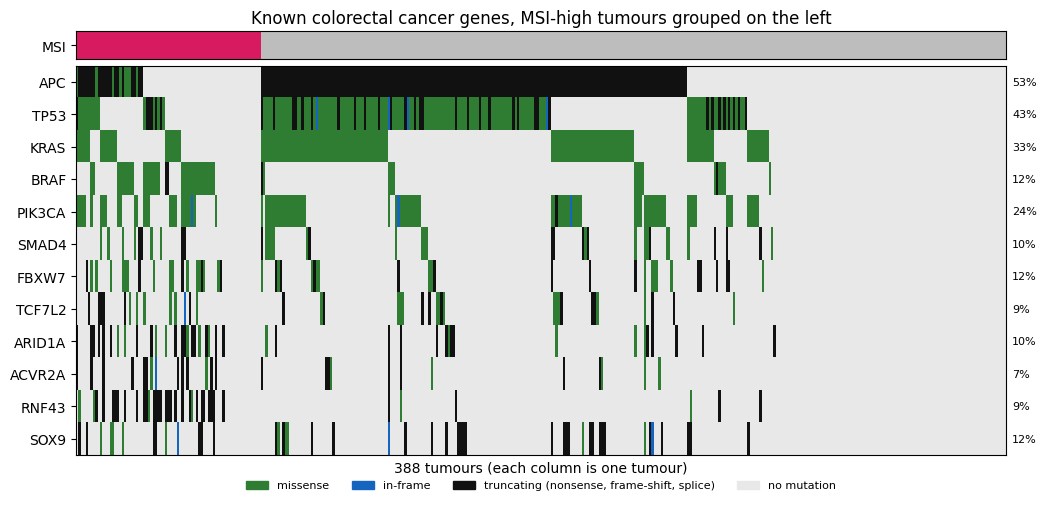

In [18]:
# Known colorectal cancer genes (Wnt pathway: APC, TCF7L2, RNF43, SOX9; RAS/MAPK/PI3K: KRAS, BRAF, PIK3CA;
# p53 and TGF-beta pathways: TP53, SMAD4, ACVR2A; others: FBXW7, ARID1A).
driver_genes = ["APC", "TP53", "KRAS", "BRAF", "PIK3CA", "SMAD4", "FBXW7", "TCF7L2", "ARID1A", "ACVR2A", "RNF43", "SOX9"]

driver_matrix = make_matrix(driver_genes)
draw_oncoprint(driver_matrix, "Known colorectal cancer genes, MSI-high tumours grouped on the left", sort_by_msi=True)

**Discussion.** Compare the MSI-high block (pink, left) with the MSS tumours. Which genes are mutated more often in one group than the other? Does APC behave differently? What does this tell you about the two groups of colon cancer? (Hint: MSI-high tumours often have BRAF mutations, and lose DNA mismatch repair.)

> **Model answer (instructor).** Approximate fractions of tumours mutated, MSI-high vs MSS: **BRAF 42% vs 5%, RNF43 39% vs 2%, ACVR2A 18% vs 4%** (much more common in MSI-high); **APC 36% vs 57%, TP53 25% vs 47%, KRAS 26% vs 35%** (less common in MSI-high); large passenger genes such as TTN are also more often mutated in MSI-high (71% vs 31%) because those tumours carry so many mutations. APC is the clearest 'driver' contrast: mutated in a bare majority of MSS tumours but only about a third of MSI-high tumours. Interpretation: colon cancer has at least two molecular routes: chromosomally unstable MSS tumours driven by APC/TP53/KRAS, and hypermutated MSI-high tumours with defective mismatch repair, BRAF (V600E) and mutations in genes with repeat tracts (ACVR2A, RNF43). The groups need different treatment (MSI-high responds to immunotherapy).

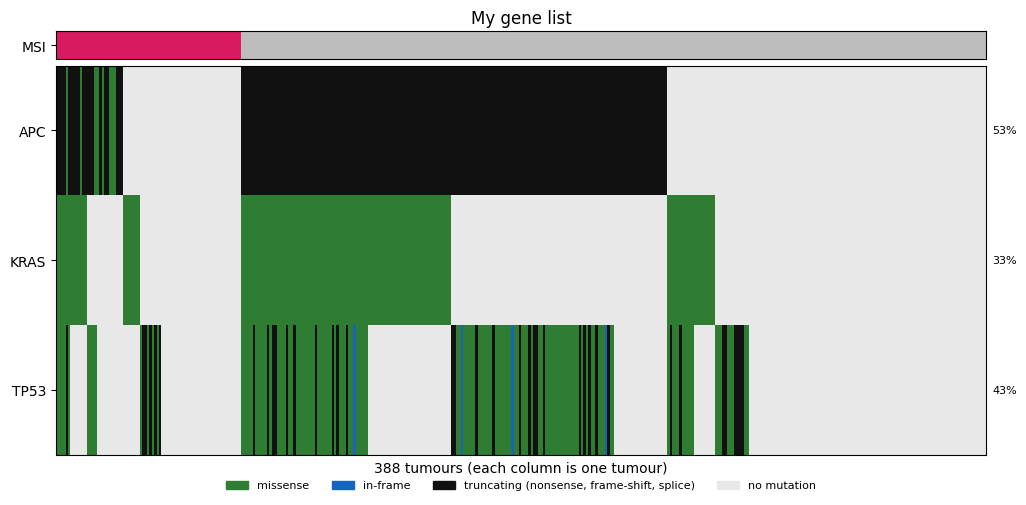

In [19]:
# Try it yourself: change the list of genes (any gene symbols in the mutation table) and run the cell again.
my_genes = ["APC", "KRAS", "TP53"]          # <- edit this list, e.g. add "PTEN", "NRAS", "CTNNB1"
draw_oncoprint(make_matrix(my_genes), "My gene list", sort_by_msi=True)

## Part 4. Expression

### 4.1 A pre-processed expression matrix

Turning raw counts into something you can compare between samples takes several steps. To save time, **we have done them for you** (the script is in the instructor files). In order, we:

1. kept only primary tumours and normal tissue, and removed duplicate vials (as in the original data);
2. kept protein-coding genes with one ID per gene symbol (as in 2.3);
3. divided each count by the sample's library size and multiplied by a million, giving **CPM** (counts per million). This corrects for samples being sequenced more or less deeply;
4. removed genes that are almost never expressed (CPM above 1 in fewer than 10% of samples);
5. took `log2(CPM + 1)` so that a few very high values do not dominate.

Two files result: the expression matrix (`logcpm`) and one row of information per sample (`info`).

In [20]:
# Load the pre-processed expression matrix (rows = genes, columns = samples) and the sample information.
logcpm = pd.read_csv(DATA / "logcpm_tumour_normal.tsv.gz", sep="\t", index_col=0)
info = pd.read_csv(DATA / "sample_info.csv", index_col=0)

# Fill in the blanks: logcpm.shape is (number of genes, number of samples)
print("number of genes:", logcpm.shape[0])
print("number of samples:", logcpm.shape[1])

print(info["type_name"].value_counts())   # how many samples of each type?
info.head()

number of genes: 14884
number of samples: 499
type_name
Primary tumour         458
Solid tissue normal     41
Name: count, dtype: int64


,type_name,annotated,tss,log10_lib_size,msi_score,msi_group,log10_tmb,site_group
sample_id,,,,,,,,
TCGA-5M-AAT6-01,Primary tumour,True,5M,7.494860,0.6600,MSI-high,3.261739,other
TCGA-AA-3552-01,Primary tumour,True,AA,7.282006,NaN,NaN,NaN,AA
TCGA-AA-3867-01,Primary tumour,True,AA,7.274504,0.3148,MSS,0.000000,AA
TCGA-AD-6895-01,Primary tumour,True,AD,7.618001,0.8416,MSI-high,3.178977,AD
TCGA-AA-3560-01,Primary tumour,True,AA,7.220240,0.3648,MSS,0.000000,AA


### 4.2 Tumour vs normal

**In plain English: PCA.** There are about 15,000 genes, so we cannot plot every sample against every gene. *Principal component analysis (PCA)* finds the directions (PC1, PC2, ...) along which the samples differ most, so each sample can be drawn as a single point. Samples that are close together have similar expression. PC1 is the biggest source of variation, PC2 the next, and so on.

The next cell defines two helper functions that run PCA and draw the plots. **You do not need to read them. Just run the cell.**

In [21]:
# HELPER FUNCTIONS - just run this cell, no changes needed.
from sklearn.decomposition import PCA

def run_pca(X, n_components=20, n_genes=2000):
    """PCA on a genes x samples table, using the n_genes most variable genes.
    Returns a samples x PCs table, and the fraction of variation each PC explains."""
    top_genes = X.var(axis=1).nlargest(n_genes).index              # the most variable genes
    samples = X.loc[top_genes].T                                   # PCA wants samples as rows
    pca = PCA(n_components=n_components).fit(samples)
    scores = pd.DataFrame(pca.transform(samples), index=X.columns,
                          columns=[f"PC{i+1}" for i in range(n_components)])
    return scores, pca.explained_variance_ratio_

def plot_pca(scores, labels, title, ax=None, pcs=("PC1", "PC2")):
    """Scatter plot of two columns of `scores`, one point per sample, coloured by `labels`."""
    ax = ax or plt.gca()
    labels = pd.Series(labels).reindex(scores.index)
    if pd.api.types.is_numeric_dtype(labels):                      # numbers -> a colour scale
        points = ax.scatter(scores[pcs[0]], scores[pcs[1]], c=labels, s=14, cmap="viridis")
        plt.colorbar(points, ax=ax, label=labels.name)
    else:                                                          # categories -> one colour per group
        labels = labels.fillna("unknown")
        for group in sorted(labels.unique()):
            m = labels == group
            ax.scatter(scores.loc[m, pcs[0]], scores.loc[m, pcs[1]], s=14, alpha=0.75, label=str(group))
        ax.legend(fontsize=7, markerscale=1.2)
    ax.set_xlabel(pcs[0]); ax.set_ylabel(pcs[1]); ax.set_title(title)

% of variation explained by PC1 to PC5: [16.6 11.7  8.7  3.8  3.4]


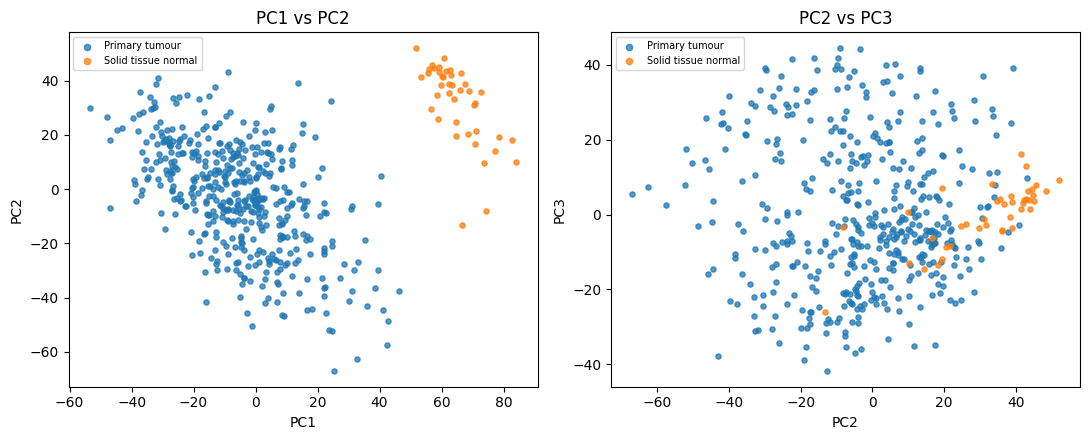

In [22]:
# Run PCA on all samples (tumours and normals).
scores, variance = run_pca(logcpm)
print("% of variation explained by PC1 to PC5:", (100 * variance[:5]).round(1))

# Plot the samples, coloured by sample type.
# Fill in the blank: which column of `info` holds the sample type? (look at info.head() above)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
plot_pca(scores, info["type_name"], "PC1 vs PC2", ax[0])
plot_pca(scores, info["type_name"], "PC2 vs PC3", ax[1], pcs=("PC2", "PC3"))
plt.tight_layout(); plt.show()

**Discussion.** Which PC separates tumour from normal best? Is it the PC with the most variation? What would you need to know about how the normal samples were collected before treating this as tumour biology?

> **Model answer (instructor).** **PC1** separates tumour from normal best (the normals sit at the right-hand side of PC1/PC2); PC1 is also the PC with most variation (about 17%), which is not guaranteed in general. Eta-squared type measures: about 0.56 of PC1 is explained by sample type, compared with about 0.002 expected by chance. To treat this as tumour biology you need to know how normals were collected: they are mostly adjacent normal tissue (different cell composition, e.g. more epithelium/muscle, not the same cell of origin), may be processed at different sites or times (batch), have systematically different library sizes (about 50M vs 35M), and are only 41 samples.

### 4.3 Is sequencing depth still visible?

Library size is a technical property, not biology. We already corrected for it with CPM. Does it still show up in the PCA? Each point below is coloured by its (log) library size.

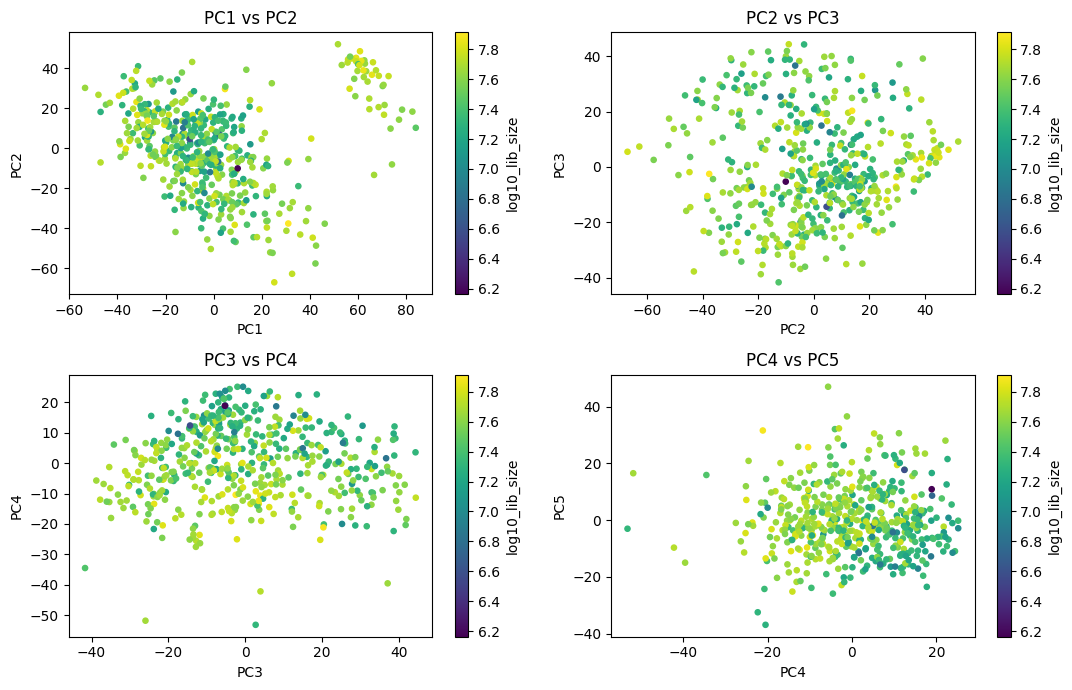

In [30]:
# Colour the same plot by library size.
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax = ax.flatten()

plot_pca(scores, info["log10_lib_size"], "PC1 vs PC2", ax[0])
plot_pca(scores, info["log10_lib_size"], "PC2 vs PC3", ax[1], pcs=("PC2", "PC3"))
plot_pca(scores, info["log10_lib_size"], "PC3 vs PC4", ax[2], pcs=("PC3", "PC4"))
plot_pca(scores, info["log10_lib_size"], "PC4 vs PC5", ax[3], pcs=("PC4", "PC5"))

plt.tight_layout()
plt.show()

**Discussion.** Do you see a colour gradient (smooth change from one colour to another) along any PC? What would that mean, and would you worry about it if you compared tumours with normals?

> **Model answer (instructor).** After CPM normalisation the colour gradient for library size is weak along PC1/PC2 but remains visible on some higher PCs (e.g. PC4, correlation about 0.4). It means some technical variation (sequencing depth) remains in the data even after library-size normalisation; it is a concern for tumour-vs-normal because normals have larger library sizes on average, so part of the difference could be technical. Accept answers that report what they see honestly, including 'not much'.

### 4.4 Tumours only: what else structures the data?

Now we look at tumours alone, and colour the PCA by three things: MSI group and mutation count (both tumour *biology*) and **tissue source site** (the hospital or centre the sample came from; sites with fewer than 10 tumours are grouped as "other").

438 tumours


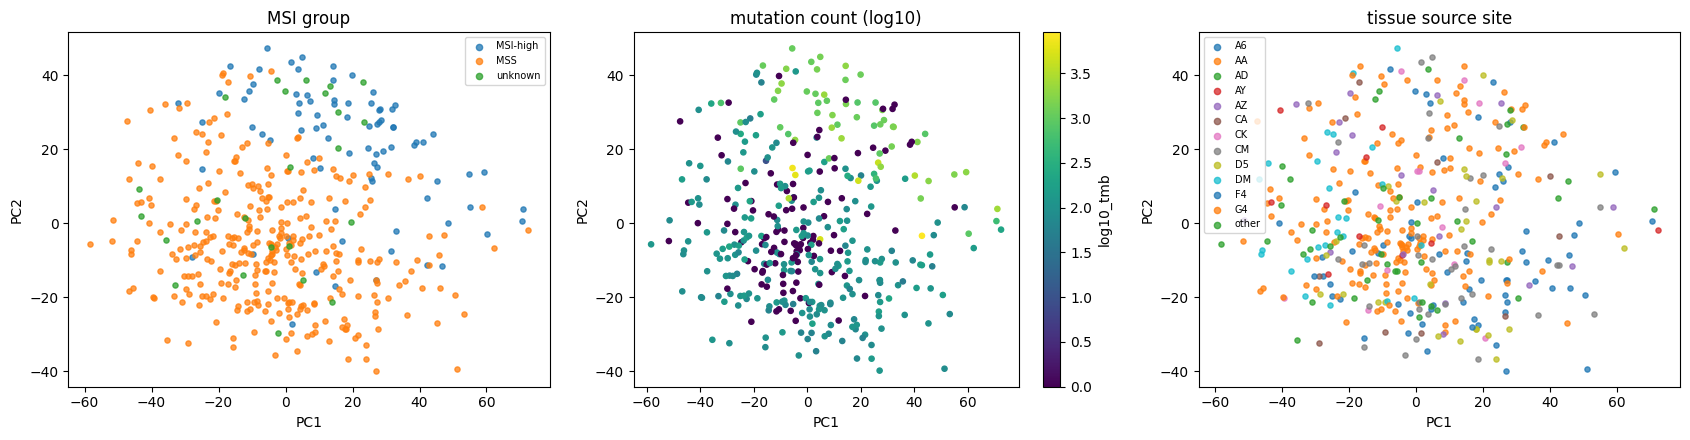

In [31]:
# Pick the primary tumours that have clinical information.
# Fill in the blank with the name of the tumour group as it appears in info["type_name"].
tumours = info.index[(info["type_name"] == "Primary tumour") & info["annotated"]]
print(len(tumours), "tumours")

# Run PCA on the tumours only.
scores_t, variance_t = run_pca(logcpm[tumours])

# Colour the same PCA three ways. Fill in the blanks with columns of `info`.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
plot_pca(scores_t, info["msi_group"], "MSI group", ax[0])
plot_pca(scores_t, info["log10_tmb"], "mutation count (log10)", ax[1])
plot_pca(scores_t, info["site_group"], "tissue source site", ax[2])
plt.tight_layout(); plt.show()

**Discussion.** Which of these three things can you see in the PCA plot? MSI and mutation count are *biology*. Is tissue source site biology? What else could make samples from the same hospital look alike?

> **Model answer (instructor).** **MSI group and mutation count are visible** (MSI separates mainly along PC2, eta-squared about 0.29 against about 0.002 chance; mutation count correlates with PCs 2-3); **tissue source site is also visible** (about 0.17 on PC1, about 0.13-0.17 on PCs 3-4, versus a chance level of about 0.03). Tissue source site is **not biology**: it is a proxy for the collecting hospital, so it can reflect batch effects (collection, fixation/freezing, shipping, RNA extraction, sequencing plate/date) or differences in patient population. It might also partly reflect real biology (e.g. MSI-high tumours being collected more at some sites, which is confounding).

### 4.5 Look at single genes

PCA summarises thousands of genes. We can also look at one gene at a time. A **boxplot** shows the middle half of the values as a box, the median as a line, and unusual values as dots.

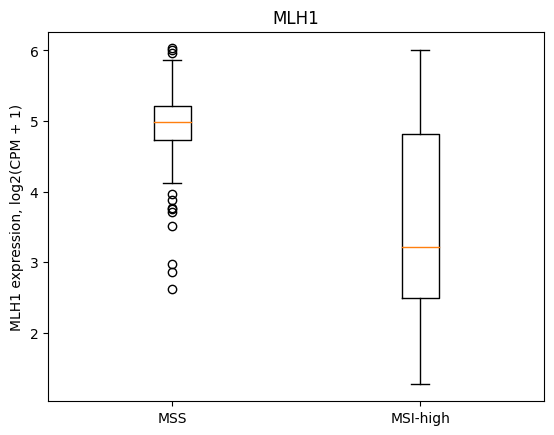

In [32]:
# MLH1 is a DNA mismatch-repair gene. When it is switched off, the cell cannot repair DNA copying errors,
# which causes microsatellite instability (MSI). Does expression of MLH1 differ between our MSI groups?
gene = "MLH1"
tumour_info = info.loc[tumours]                                        # the primary tumours from 4.4
expression = logcpm.loc[gene, tumours]                                 # expression of that gene in those tumours

groups = [expression[tumour_info["msi_group"] == g] for g in ["MSS", "MSI-high"]]
plt.boxplot(groups, labels=["MSS", "MSI-high"])
plt.ylabel(f"{gene} expression, log2(CPM + 1)"); plt.title(gene); plt.show()

**Discussion.** What do you see? Does this fit with what you know about MSI? Was this a mutation effect or something else? (Think about the oncoprint: you could check whether MLH1 is mutated in these tumours, but MLH1 is more often silenced by DNA methylation.)

> **Model answer (instructor).** MLH1 is clearly **lower in MSI-high tumours** (median log2 CPM about 3.2 vs about 5.0 in MSS). It fits: loss of MLH1 causes mismatch-repair deficiency and MSI. It is probably not due to MLH1 mutation: in sporadic MSI-high colon cancer MLH1 is most often silenced epigenetically by promoter hypermethylation (CIMP), which this mutation table cannot show, so expression adds information that the mutation data would miss. (Lynch syndrome cases with germline MLH1 mutation are the minority.)

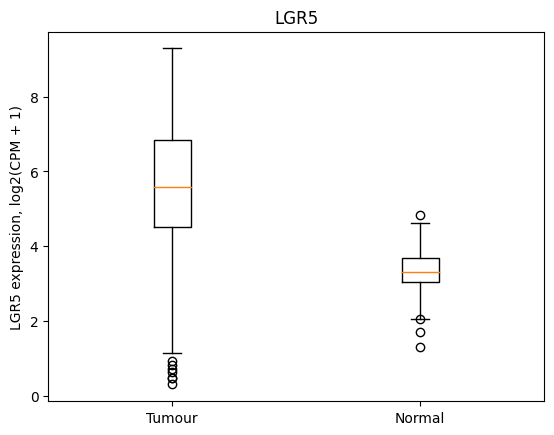

In [33]:
# Now choose your own gene and compare tumours with normal tissue.
# Fill in a gene symbol. Suggestions: "LGR5" (a colon stem-cell marker), "CDX2", "MYC", "KRAS", "TP53".
gene = "LGR5"
expression = logcpm.loc[gene]
types = ["Primary tumour", "Solid tissue normal"]
groups = [expression[info["type_name"] == t] for t in types]
plt.boxplot(groups, labels=["Tumour", "Normal"])
plt.ylabel(f"{gene} expression, log2(CPM + 1)"); plt.title(gene); plt.show()

**Discussion.** Is your gene higher in tumour or normal tissue? Would you trust this for a gene where you only had three normal samples? How many normal samples do we have here?

> **Model answer (instructor).** LGR5 (a stem-cell marker) is higher in tumours (median about 5.6 vs about 3.3 in normals). Any sensible gene is acceptable if the answer is read from the plot, e.g. MYC higher in tumours, CDX2 about the same. We have **41 normal samples**; with only 3 normals you could not estimate normal variation, a boxplot would be misleading, and a test would have little power. Also remember the normals are not an independent, ideal control (adjacent tissue, different collection).

## Part 5. Judgement

### 5.1 t-SNE is not PCA

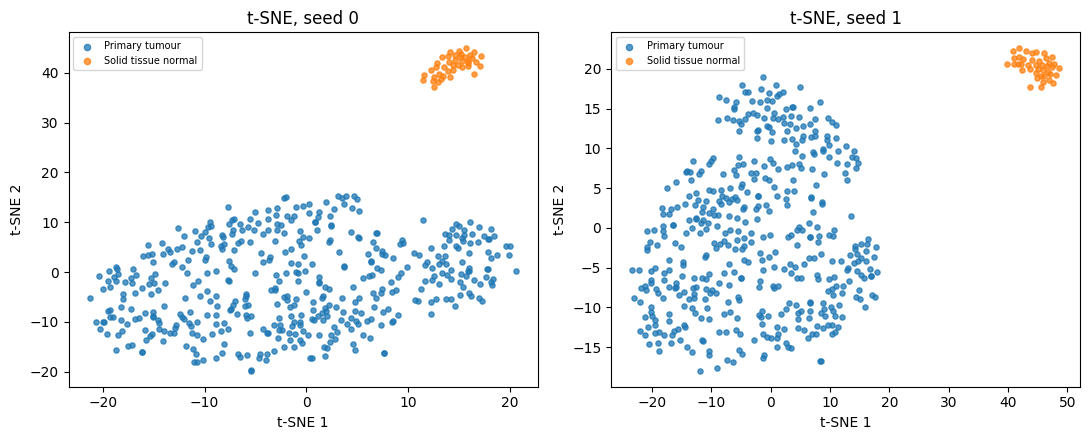

In [34]:
# t-SNE is a non-linear 2D embedding. Here it is run on the first 20 PCs of the normalised data.
from sklearn.manifold import TSNE

# Run t-SNE twice on the same data, changing ONLY the random seed.
# (init="random" makes the starting layout depend on the seed, so the effect of the seed is easy to see.)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, seed in zip(ax, (0, 1)):
    tsne = TSNE(n_components=2, perplexity=30, init="random", random_state=seed)
    embedding = tsne.fit_transform(scores.iloc[:, :20].to_numpy())
    emb = pd.DataFrame(embedding, index=scores.index, columns=["t-SNE 1", "t-SNE 2"])
    plot_pca(emb, info["type_name"], f"t-SNE, seed {seed}", a, pcs=("t-SNE 1", "t-SNE 2"))
plt.tight_layout(); plt.show()

**Discussion.** What is the same between the two plots and what is different? Would you report the distance between two clusters in a t-SNE plot as a result? Why or why not?

> **Model answer (instructor).** Same: the normals form a separate cluster from the tumours in both plots, and the tumours form a broad cloud. Different: the position and orientation of clusters, the distances between them and the number/shape of sub-groups within the tumours change with the random seed (t-SNE starts from a random layout). Do **not** report distances between clusters or cluster sizes as results: t-SNE preserves local neighbourhoods but not global distances, and the layout depends on seed and perplexity. Fine to say 'normals form a distinct group'. A better check is to run several seeds/perplexities and confirm with PCA.

### 5.2 Wrap-up

Discussion points:

- **Curation choices.** Name two things in this dataset that came from *curation choices* (yours or ours), not from the biology, and say how each could change a downstream result.
- **Documentation.** What would you want written in the README of a dataset like this, so that someone in a year could reuse it safely? What are the five most important items?
- **Batch effects.** Think about the tissue-source-site results in Part 4.4 (tissue source site). What additional data, or what change to the study design, would let you say whether site effects are batch effects?

> **Model answer (instructor).** Marking guide, any two well-argued points. **Curation choices**, e.g.: (1) the FILTER decision (PASS only) changes mutation counts and driver frequencies; (2) which variant classes count as non-silent (e.g. Splice_Site); (3) the MSI cut-off changes who is in the MSI-high group; (4) which duplicate vial is kept, or which genes are kept (protein-coding, highest-expressed ID per symbol, CPM > 1 in 10% of samples); (5) whether tumours with no mutation data are dropped or counted as zero. **README** (five items, e.g.): data source and download date/version; genome build and annotation version for each file; processing level and transform of the matrix (log2(count + 1), CPM or raw); which samples/genes were removed and why (filters, duplicates, cut-offs); how identifiers map between files (barcode structure, gene IDs to symbols) and sample counts per group; known caveats (batch/site, normals, purity); and the script that produced it. **Batch effects**: need the technical metadata (collection site, plate, sequencing date, extraction batch, RNA quality), ideally samples from the same tissue/patients processed in several batches (replicates or reference samples across batches), a balanced design in which each batch contains both tumours and normals and different MSI groups, and/or a statistical model that includes site and MSI together to see whether the site effect remains after adjusting.